# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170091  # <-- your full roll number
NAME = "Jasleen Kaur"  # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170091   Name: Jasleen Kaur   Fingerprint: A8E3F53A   Tickets: 13

Ticket_ID                                                                              Ticket_Text
      T01                                      The VPN is not working. I have tried several times!
      T02        Python is showing an error after the latest update. It works on another computer.
      T03                                              The Python stopped responding. Please help.
      T04                                           Re-installing didn't help; log-in still fails!
      T05                                   I can't open the LMS on my laptop. Can you check this?
      T06                                                              My roll no. is 1023-03-021.
      T07           Server keeps asking for login after restarting the system. Can you check this?
      T08               Projector has stopped syncing while uploading the file. Please resolve it.
      T09                

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
from collections import Counter, defaultdict

results = {r.Ticket_ID: process_ticket(r.Ticket_Text) for r in df.itertuples()}

rows = []
for tid, res in results.items():
    rows.append({"Ticket_ID": tid,
                 "Sentences": len(res["sentences"]),
                 "Tokens": len(res["tokens"]),
                 "Punctuation": len(res["punct"]),
                 "Stopwords": len(res["stops"]),
                 "Unique_Tokens": len(set(res["tokens"])),
                 "Final_Tokens": len(res["final"])})
q1 = pd.DataFrame(rows)
total = q1.drop(columns="Ticket_ID").sum()
q1.loc[len(q1)] = ["TOTAL"] + total.tolist()
print(q1.to_string(index=False))
print("\n(Unique_Tokens = distinct lowercase tokens within each ticket; the TOTAL row is the sum of those per-ticket counts.)")
print("Distinct tokens across the whole corpus:", len({t for r in results.values() for t in r["tokens"]}))

# Detailed view of the two focus tickets
for tid in FOCUS:
    res = results[tid]
    print("\n" + "=" * 70)
    print(f"{tid}: {df.loc[df.Ticket_ID == tid, 'Ticket_Text'].iloc[0]}")
    print("Sentences  :", res["sentences"])
    print("Tokens     :", res["tokens"])
    print("Punctuation:", res["punct"])
    print("Stopwords  :", res["stops"])
    print("Final      :", res["final"])

# For the Observe question: final tokens that are not real words
print("\n" + "=" * 70)
print("Final tokens that are not ordinary words (ticket -> token):")
for tid, res in results.items():
    odd = [t for t in res["final"] if t.startswith("'") or t == "n't" or t in {"ca", "wo", "sha"}]
    if odd:
        print(f"  {tid}: {odd}   <- from: {df.loc[df.Ticket_ID == tid, 'Ticket_Text'].iloc[0]}")
print("Final tokens that are numbers / hyphenated / contain symbols:")
print(" ", sorted({t for r in results.values() for t in r["final"] if not t.isalpha()}))


Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      12            2          5             12             5
      T02          2      16            2          6             15             8
      T03          2       8            2          1              7             5
      T04          1       9            2          1              9             6
      T05          2      15            2          7             15             6
      T06          2       7            2          3              6             2
      T07          2      15            2          6             15             7
      T08          2      13            2          4             12             7
      T09          1       7            2          2              7             3
      T10          2      16            2          7             14             7
      T11          2      16            2          6             15             8
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

**Your answer:** Two final tokens are not real words: **`n't`** (in T04 and T05) and **`ca`** (in T05). They come from `word_tokenize`, which follows Penn Treebank rules and splits contractions: *didn't* becomes `did` + `n't` and *can't* becomes `ca` + `n't`. The stopword list contains `did` (so it is dropped) but not `n't` or `ca`, so these fragments survive into the final tokens. The other non-alphabetic final tokens (`1023-03-021`, `95.5`, `e-mail`, `log-in`, `re-installing`) are genuine single tokens, not errors.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
import re
from nltk.tokenize import sent_tokenize

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# ---------- findall patterns ----------
LONG_WORDS = r"(?<![\w'@/.])[A-Za-z]{6,}(?![\w'@/])(?!\.\w)"       # more than 5 letters; ignores pieces of emails/URLs
NUMBERS    = r"(?<![\w.])\d+(?:[.,]\d+)*(?!\w)"                      # 95.5, 2.0.1, 1,250, 5.30 stay whole
CAPITAL    = r"\b[A-Z][a-z]*(?:-[A-Za-z]+)*\b"                       # Python, Wi-Fi, I  (not LMS / VPN)
VOWEL      = r"(?<![\w'@/.-])[AEIOUaeiou][A-Za-z]*(?:'[A-Za-z]+)?(?![\w'@/-])(?!\.\w)"  # isn't kept whole, e-mail / emails / URLs not split

# ---------- sub patterns ----------
EMAIL = r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b"
URL   = r"(?:https?://|www\.)[^\s<>]*[\w/]"                          # last char is not trailing punctuation
PHONE = r"(?<![\w-])(?:\+\d{1,3}[\s-]\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4}|\d{5}[\s-]\d{5})(?![\w-])"

def extract(text):
    return {"long (>5)": re.findall(LONG_WORDS, text),
            "numbers": re.findall(NUMBERS, text),
            "capitalized": re.findall(CAPITAL, text),
            "vowel-start": re.findall(VOWEL, text)}

def clean(text):
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL, "<URL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

print("=== findall on TEST_LINES ===")
for line in TEST_LINES:
    print("\n", line)
    for k, v in extract(line).items():
        print(f"   {k:12s}: {v}")

print("\n=== re.sub on TEST_LINES ===")
for line in TEST_LINES:
    print("\n IN :", line)
    print(" OUT:", clean(line))

print("\n=== findall on your raw tickets ===")
q2 = pd.DataFrame([{"Ticket_ID": r.Ticket_ID, **{k: ", ".join(v) for k, v in extract(r.Ticket_Text).items()}}
                   for r in df.itertuples()])
pd.set_option("display.max_colwidth", 80, "display.width", 250)
print(q2.to_string(index=False))

print("\n=== re.sub on your raw tickets (only tickets that change) ===")
changed = [(r.Ticket_ID, r.Ticket_Text, clean(r.Ticket_Text)) for r in df.itertuples() if clean(r.Ticket_Text) != r.Ticket_Text]
print(changed if changed else "No ticket in this dataset contains an email, URL or phone number, so nothing is replaced (patterns are demonstrated on TEST_LINES).")

# ---- for the Observe question ----
init, non_init = 0, []
for t in df.Ticket_Text:
    for s in sent_tokenize(t):
        for m in re.finditer(CAPITAL, s):
            if m.start() == 0:
                init += 1
            else:
                non_init.append(m.group())
print(f"\nCapitalized words total: {init + len(non_init)}")
print(f"  sentence-initial: {init}")
print(f"  not sentence-initial ({len(non_init)}): {non_init}")


=== findall on TEST_LINES ===

 Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
   long (>5)   : []
   numbers     : []
   capitalized : ['Mail']
   vowel-start : ['or', 'or']

 Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
   long (>5)   : ['Version']
   numbers     : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
   capitalized : ['Call', 'Version', 'Rs']
   vowel-start : ['or', 'is']

 The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
   long (>5)   : []
   numbers     : ['5.30']
   capitalized : ['The']
   vowel-start : ["isn't", 'open', 'at']

=== re.sub on TEST_LINES ===

 IN : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
 OUT: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

 IN : Call +91 98765 43210, +91-98765-43210 or 0175-239-320

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

**Your answer:** **22 of the 23** capitalized words are capitalized only because they start a sentence (The, I, It, Please, Server, Projector, My, Can, Nothing ...). Only **1** (`Python` in T03, "The Python stopped responding") is capitalized mid-sentence, as a proper noun. So a plain capitalized-word regex mostly detects sentence boundaries here, not names.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

TOKEN_PATTERN = r"""(?x)
    (?:[\w.+-]+@[\w-]+(?:\.[\w-]+)+)                                   # email
  | (?:(?:https?://|www\.)[^\s<>]*[\w/])                               # URL
  | (?:\+\d{1,3}[\s-]\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4}|\d{5}[\s-]\d{5}) # phone number
  | (?:\d+(?:-\d+)+)                                                   # digit groups such as 1023-03-021
  | (?:0[xX][0-9A-Fa-f]+)                                              # hex codes such as 0x80070005
  | (?:\d+(?:[.,]\d+)*)                                                # integers, decimals (95.5), versions (2.0.1)
  | (?:(?:[A-Za-z]\.){2,})                                             # abbreviations such as p.m.
  | (?:[A-Za-z][A-Za-z0-9]*(?:['\u2019-][A-Za-z0-9]+)*)                # words, contractions (isn't), hyphenated (Wi-Fi)
  | (?:\.{3})                                                          # ellipsis
  | (?:[^\w\s])                                                        # any other single punctuation mark
"""
_tok = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _tok.tokenize(text)

print("=== TEST_LINES ===")
for line in TEST_LINES:
    print("\n", line)
    print("  my_tokenize  :", my_tokenize(line))
    print("  word_tokenize:", word_tokenize(line))

# compare on tickets
diff_rows = []
for r in df.itertuples():
    a, b = my_tokenize(r.Ticket_Text), word_tokenize(r.Ticket_Text)
    if a != b:
        ca, cb = Counter(a), Counter(b)
        diff_rows.append({"Ticket_ID": r.Ticket_ID,
                          "only my_tokenize": list((ca - cb).elements()),
                          "only word_tokenize": list((cb - ca).elements())})
print(f"\n=== Tickets tokenized differently: {len(diff_rows)} of {len(df)} ===")
print(pd.DataFrame(diff_rows).to_string(index=False) if diff_rows else "none")

# side-by-side table of the tricky cases (the pieces the assignment asks about)
cases = ["isn't", "didn't", "Wi-Fi", "state-of-the-art", "95.5%", "Version 2.0.1", "5.30 p.m.", "it.helpdesk@thapar.edu",
         "https://lms.thapar.edu/help", "+91 98765 43210", "0175-239-3201", "1023-03-021", "Rs 1,250"]
cmp_table = pd.DataFrame({"Text": cases,
                          "word_tokenize": [word_tokenize(c) for c in cases],
                          "my_tokenize": [my_tokenize(c) for c in cases]})
print("\n=== Side-by-side comparison on tricky cases ===")
print(cmp_table.to_string(index=False))


=== TEST_LINES ===

 Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

 Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  my_tokenize  : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

 The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't 

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

**Your answer:** **2 of the 13 tickets** are tokenized differently: **T04** (*didn't* is `didn't` in my_tokenize but `did` + `n't` in word_tokenize) and **T05** (*can't* is `can't` vs `ca` + `n't`). The other 11 tickets are identical because my_tokenize also keeps punctuation as separate tokens and none of them contain an email, URL or phone number. On TEST_LINES all 3 lines differ (emails, URLs, phone numbers, contractions and `p.m.`).

**Differences between word_tokenize and my_tokenize (see the comparison table above):**
1. *Contractions* - `isn't`, `didn't`: word_tokenize splits off `n't` (and leaves `is`, `did`); my_tokenize keeps the contraction as one token.
2. *Email* - `it.helpdesk@thapar.edu`: word_tokenize breaks it at `@` into `it.helpdesk`, `@`, `thapar.edu`; my_tokenize keeps one token.
3. *URL* - `https://lms.thapar.edu/help`: word_tokenize splits at the colon into `https`, `:`, `//lms.thapar.edu/help`; my_tokenize keeps one token.
4. *Phone with country code* - `+91 98765 43210`: word_tokenize gives `+91`, `98765`, `43210`; my_tokenize gives one token.
5. *Abbreviation* - `5.30 p.m.`: word_tokenize gives `p.m` and `.`, my_tokenize keeps `p.m.` together.
Hyphenated words (`Wi-Fi`, `state-of-the-art`, `log-in`), decimals (`95.5`) and versions (`2.0.1`) are already kept whole by word_tokenize, so those do not differ.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

all_final = [t for r in results.values() for t in r["final"]]
unique_final = sorted(set(all_final))

# Choose the Regexp suffix after looking at the data
ing_words = [w for w in unique_final if w.endswith("ing")]
print("Unique final tokens ending in 'ing':", ing_words)

porter, lancaster = PorterStemmer(), LancasterStemmer()
regexp = RegexpStemmer(r"ing$", min=4)     # strip a trailing 'ing' (only from words of 4+ letters)
lemm = WordNetLemmatizer()

# POS tags: tag each ticket in its original case (context + capitalisation help the tagger), then keep the commonest tag per word
tag_counts = defaultdict(Counter)
for res in results.values():
    original_case = [t for sent in res["sentences"] for t in word_tokenize(sent)]
    for w, tag in pos_tag(original_case):
        tag_counts[w.lower()][tag] += 1

def to_wn(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

rows = []
for w in unique_final:
    tag = tag_counts[w].most_common(1)[0][0]
    rows.append({"Word": w, "POS": tag,
                 "Porter": porter.stem(w), "Lancaster": lancaster.stem(w),
                 "Regexp(ing$)": regexp.stem(w), "WordNet_Lemma": lemm.lemmatize(w, to_wn(tag))})
q4 = pd.DataFrame(rows)
outs = ["Porter", "Lancaster", "Regexp(ing$)", "WordNet_Lemma"]
q4_diff = q4[q4[outs].nunique(axis=1) > 1].reset_index(drop=True)

print(f"\n{len(q4)} unique final tokens, {len(q4_diff)} of them get different outputs:\n")
print(q4_diff.to_string(index=False))


Unique final tokens ending in 'ing': ['asking', 'nothing', 're-installing', 'resetting', 'responding', 'restarting', 'showing', 'syncing', 'uploading', 'working']



55 unique final tokens, 32 of them get different outputs:

         Word POS    Porter     Lancaster Regexp(ing$) WordNet_Lemma
      another  DT     anoth         anoth      another       another
     computer  NN    comput        comput     computer      computer
        error  NN     error            er        error         error
        fails VBZ      fail          fail        fails          fail
         file  NN      file           fil         file          file
        keeps VBZ      keep          keep        keeps          keep
       latest JJS    latest        latest       latest          late
          lms NNP        lm           lms          lms            lm
       nobody  NN    nobodi        nobody       nobody        nobody
      nothing  NN      noth          noth         noth       nothing
       occurs VBZ     occur           occ       occurs         occur
         open  VB      open            op         open          open
       please NNP     pleas         pleas  

**Observe:** Give one over-stemming and one under-stemming example from your table.

**Your answer:** **Regexp suffix choice: `ing$` (min length 4).** In my data, 10 unique final tokens end in *-ing*, e.g. `working` (T01, T13), `uploading` (T08), `showing` (T02), `syncing` (T08), `responding` (T03). Stripping *-ing* gives the correct base word for most of them (`work`, `upload`, `show`, `respond`, `ask`, `restart`), and it is a simple, predictable rule. `min=4` stops very short words being destroyed. Its weaknesses are visible in the table: `resetting` becomes `resett` (doubled consonant) and `nothing` becomes `noth`; it also does nothing for `-ed`/`-s` forms.

**Over-stemming:** Lancaster turns `unable` into `un` (and `projector` into `project`, merging two different words; `error` into `er`) - too much of the word is cut away, so different words collide.

**Under-stemming:** the Regexp stemmer leaves `uploaded` as `uploaded` but turns `uploading` into `upload`, so words of the same family get different stems (Porter and Lancaster both map them to `upload`). Similarly Porter maps `replied` to `repli`, while Lancaster gives `reply`.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

              Set  Tokens  Unique    TTR
    S1 all tokens     155      85 0.5484
S2 no punctuation     130      80 0.6154
  S3 final tokens      75      55 0.7333
   S4 S3 + Porter      75      53 0.7067

Top 10 words of S1: [('.', 18), ('the', 11), ('i', 5), ('is', 4), ('tried', 3), ('!', 3), ('after', 3), ('it', 3), ('works', 3), ('on', 3)]
Top 10 words of S3: [('tried', 3), ('works', 3), ('working', 2), ('several', 2), ('times', 2), ('python', 2), ('another', 2), ('computer', 2), ('stopped', 2), ('please', 2)]


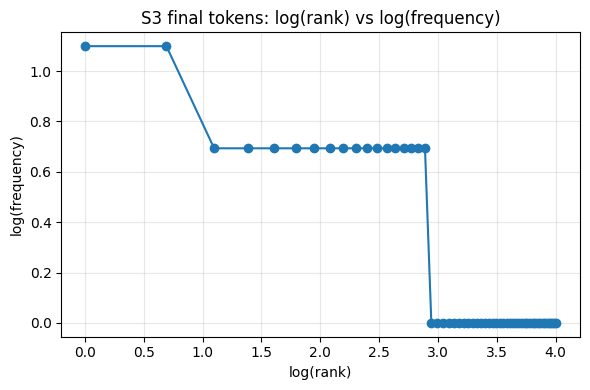


Top 5 bigrams of S1: [(('.', 'i'), 2), (('i', 'have'), 2), (('have', 'tried'), 2), (('tried', 'several'), 2), (('several', 'times'), 2)]
Top 5 bigrams of S3: [(('tried', 'several'), 2), (('several', 'times'), 2), (('works', 'another'), 2), (('another', 'computer'), 2), (('vpn', 'working'), 1)]


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from nltk import bigrams

S1 = [t for r in results.values() for t in r["tokens"]]                         # all tokens
S2 = [t for t in S1 if not is_punct(t)]                                        # no punctuation
S3 = [t for r in results.values() for t in r["final"]]                         # final tokens
S4 = [porter.stem(t) for t in S3]                                              # S3 after Porter

stats = pd.DataFrame([{"Set": n, "Tokens": len(s), "Unique": len(set(s)), "TTR": round(len(set(s)) / len(s), 4)}
                      for n, s in [("S1 all tokens", S1), ("S2 no punctuation", S2), ("S3 final tokens", S3), ("S4 S3 + Porter", S4)]])
print(stats.to_string(index=False))

print("\nTop 10 words of S1:", Counter(S1).most_common(10))
print("Top 10 words of S3:", Counter(S3).most_common(10))

# Zipf plot for S3
freq = Counter(S3)
counts = np.array(sorted(freq.values(), reverse=True))
ranks = np.arange(1, len(counts) + 1)
plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(counts), "o-")
plt.xlabel("log(rank)"); plt.ylabel("log(frequency)")
plt.title("S3 final tokens: log(rank) vs log(frequency)")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# Bigrams are built inside each ticket so that no bigram spans two different tickets
def ticket_bigrams(key):
    out = []
    for r in results.values():
        out += list(bigrams(r[key]))
    return out

print("\nTop 5 bigrams of S1:", Counter(ticket_bigrams("tokens")).most_common(5))
print("Top 5 bigrams of S3:", Counter(ticket_bigrams("final")).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

**Your answer:** TTR rises from **0.548 (S1)** to **0.615 (S2)** and **0.733 (S3)**, then drops slightly to **0.707 (S4)**. Removing punctuation deletes 25 tokens but only 5 unique types (the `.` alone occurs 18 times), and removing stopwords deletes another 55 tokens but only 25 types (`the` occurs 11 times), so the tokens shrink much faster than the types and the ratio rises. Porter stemming does not change the token count (75) but merges 2 pairs of types (`working`/`works` -> `work`, `uploaded`/`uploading` -> `upload`), lowering unique tokens from 55 to 53, so TTR falls to 0.707.

---
## Q6. Interpretation
Brief answers, each backed by the evidence printed in the next cell.

In [10]:
# Evidence used for the Q6 answers (all computed from this dataset)
print("(a) TTR by set:", dict(zip(stats["Set"], stats["TTR"])))
print("    stems merged by Porter:", {k: sorted({w for w in set(S3) if porter.stem(w) == k}) for k in set(S4)
      if len({w for w in set(S3) if porter.stem(w) == k}) > 1})
print("(b) word_tokenize vs my_tokenize:")
for c in ["didn't", "Wi-Fi", "5.30 p.m."]:
    print(f"    {c!r}: word_tokenize={word_tokenize(c)}  my_tokenize={my_tokenize(c)}")
print("(c) Stemmer outputs for risky words:")
print(q4[q4.Word.isin(["several", "tried", "unable", "nothing", "lms", "replied", "occurs"])].to_string(index=False))
print("(d) Lemmatizer with vs without POS:")
for w in ["tried", "stopped", "replied", "occurs"]:
    tag = q4.loc[q4.Word == w, "POS"].iloc[0]
    print(f"    {w:8s} Porter={porter.stem(w):7s} lemmatize(no POS)={lemm.lemmatize(w):8s} lemmatize(POS={tag}->{to_wn(tag)})={lemm.lemmatize(w, to_wn(tag))}")


(a) TTR by set: {'S1 all tokens': 0.5484, 'S2 no punctuation': 0.6154, 'S3 final tokens': 0.7333, 'S4 S3 + Porter': 0.7067}
    stems merged by Porter: {'upload': ['uploaded', 'uploading'], 'work': ['working', 'works']}
(b) word_tokenize vs my_tokenize:
    "didn't": word_tokenize=['did', "n't"]  my_tokenize=["didn't"]
    'Wi-Fi': word_tokenize=['Wi-Fi']  my_tokenize=['Wi-Fi']
    '5.30 p.m.': word_tokenize=['5.30', 'p.m', '.']  my_tokenize=['5.30', 'p.m.']
(c) Stemmer outputs for risky words:
   Word POS Porter Lancaster Regexp(ing$) WordNet_Lemma
    lms NNP     lm       lms          lms            lm
nothing  NN   noth      noth         noth       nothing
 occurs VBZ  occur       occ       occurs         occur
replied VBN  repli     reply      replied         reply
several  JJ  sever       sev      several       several
  tried VBN    tri       tri        tried           try
 unable  JJ  unabl        un       unable        unable
(d) Lemmatizer with vs without POS:
    tried    Por

### Answers

**(a) Why TTR changes from S1 to S4.** TTR = unique tokens / total tokens. From S1 (0.548) to S2 (0.615) to S3 (0.733) it increases because the removed items (punctuation: 25 tokens, 5 types; stopwords: 55 tokens, 25 types) are very repetitive, e.g. `.` appears 18 times and `the` 11 times. Removing them cuts the total much more than the number of distinct types. From S3 to S4 (0.733 -> 0.707) the total stays at 75 but stemming merges variants (`working`, `works` -> `work`; `uploaded`, `uploading` -> `upload`), so unique tokens fall from 55 to 53.

**(b) word_tokenize vs my_tokenize.** For `didn't` (ticket T04), `word_tokenize` returns `['did', "n't"]` because the Treebank tokenizer splits contractions, whereas `my_tokenize` returns `["didn't"]` because its word pattern allows an apostrophe inside a word. The same happens for `can't` in T05 (`ca` + `n't`). Another example: for `it.helpdesk@thapar.edu` word_tokenize gives three tokens (`it.helpdesk`, `@`, `thapar.edu`), my_tokenize gives one.

**(c) Undesirable stemming.** Porter stems `several` (T01, T13) to `sever`, which is a different word meaning "to cut", so a search for *sever* would wrongly match *several*. Porter also turns `tried` into `tri`, which is not a word, and Lancaster turns `unable` into `un`, discarding the meaning.

**(d) POS-aware lemmatization.** `tried` (tagged VBN) is lemmatized to `try` when the verb POS is passed, a real word with the right meaning, while Porter gives the non-word `tri`. Without the POS the lemmatizer would treat it as a noun and leave `tried` unchanged. The same applies to `replied` -> `reply` (Porter: `repli`) and `stopped` -> `stop`.